In [ ]:
!pip install -q catboost shap

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({'figure.figsize': (12, 4), 'axes.grid': True, 'grid.alpha': 0.3})

BASE = '/content/drive/MyDrive/geomacro'
RAW = f'{BASE}/raw'

market = pd.read_parquet(f'{RAW}/market.parquet')
fred   = pd.read_parquet(f'{RAW}/fred.parquet')
gdelt  = pd.read_parquet(f'{RAW}/gdelt_daily.parquet')
for d in (market, fred, gdelt):
    d['date'] = pd.to_datetime(d['date']).astype('datetime64[ns]')

for name, d in [('market', market), ('fred', fred), ('gdelt', gdelt)]:
    print(f"{name:7s} {d.shape}  {d['date'].min().date()} -> {d['date'].max().date()}")

report = json.load(open(f'{RAW}/validation_report.json'))
print(f"\nLaporan validasi: {report['n_errors']} ERROR, {report['n_warnings']} WARNING")
for i in report['issues']:
    if i['level'] != 'INFO':
        print(f" - [{i['level']}] {i['source']} | {i['check']}: {i['detail']}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
market  (2236, 7)  2018-01-02 -> 2026-11-13
fred    (2507, 5)  2017-01-01 -> 2026-11-10
gdelt   (3222, 12)  2018-01-01 -> 2026-11-16

Laporan validasi: 0 ERROR, 2 WARNING
 - [WARNING] gdelt | tanggal_bolong: 11 kolom (n_events, n_verbal_conflict, n_material_conflict, ...): 20 hari hilang -> ['2022-11-10', '2023-03-23', '2025-06-14 s/d 2025-07-01']
 - [WARNING] gdelt | hari_sepi: 4 hari dengan n_events < 20% median (123905), kemungkinan file parsial: ['2020-11-07', '2020-11-13', '2020-11-14', '2020-11-15']


In [ ]:
import re
FIG_DIR = f'{BASE}/figures'
os.makedirs(FIG_DIR, exist_ok=True)
_fig_n = [0]
_orig_show = plt.show

def _slug(s):
    return re.sub(r'[^a-z0-9]+', '_', s.lower()).strip('_')[:60] or 'grafik'

def _show_and_save(*a, **k):
    fig = plt.gcf()
    sup = getattr(fig, '_suptitle', None)
    title = sup.get_text() if sup is not None else (fig.axes[0].get_title() if fig.axes else '')
    _fig_n[0] += 1
    fig.savefig(f'{FIG_DIR}/{_fig_n[0]:02d}_{_slug(title)}.png', dpi=150, bbox_inches='tight')
    _orig_show(*a, **k)
    plt.close(fig)          # pastikan grafik berikutnya (mis. SHAP) mulai di figure baru

plt.show = _show_and_save
print('Grafik akan tersimpan otomatis di', FIG_DIR)

Grafik akan tersimpan otomatis di /content/drive/MyDrive/geomacro/figures


In [ ]:
display(market.describe().T.round(2))
display(fred.describe().T.round(2))
display(gdelt.drop(columns='date').describe().T.round(3))

,count,mean,min,25%,50%,75%,max,std
date,2236,2022-06-10 20:51:18.354203904,2018-01-02 00:00:00,2020-03-23 18:00:00,2022-06-09 12:00:00,2024-08-29 06:00:00,2026-11-13 00:00:00,NaN
oil_close,2232.0,69.431174,-37.630001,59.375001,69.209999,79.482502,123.699997,17.522826
dxy_close,2232.0,99.040083,88.589996,95.767498,98.599998,103.012501,114.110001,5.090398
gold_close,2232.0,2230.453718,1176.199951,1639.200012,1868.650024,2538.675049,5318.399902,993.098014
sp500_close,2229.0,4454.200413,2237.399902,3116.389893,4187.620117,5521.52002,7818.930176,1461.444659
vix_close,2231.0,19.605325,9.15,15.025,17.780001,22.24,82.690002,7.176778
sp500_volume,2229.0,4388469708.389412,0.0,3648720000.0,4148500000.0,4940120000.0,10025820000.0,1095053928.938653


,count,mean,min,25%,50%,75%,max,std
date,2507,2021-12-05 21:06:32.022337536,2017-01-01 00:00:00,2019-06-19 12:00:00,2021-12-06 00:00:00,2024-05-26 00:00:00,2026-11-10 00:00:00,NaN
yield_10y,2465.0,2.943391,0.52,1.87,2.89,4.16,5.31,1.249663
yield_2y,2465.0,2.614957,0.09,1.34,2.61,4.08,5.19,1.593144
cpi,117.0,283.575658,243.618,255.296,278.919,313.023,337.476,30.433155
fed_funds,118.0,2.498644,0.05,0.8175,2.235,4.33,5.33,1.868174


,count,mean,std,min,25%,50%,75%,max
n_events,3222.0,125611.091,39065.698,16508.000,97061.500,123905.500,150980.000,239009.000
n_verbal_conflict,3222.0,16145.555,5152.823,1998.000,12434.250,15886.500,19462.000,32352.000
n_material_conflict,3222.0,17471.561,5328.293,2319.000,13765.500,16991.500,20981.250,34082.000
n_violent,3222.0,9667.891,2880.075,1291.000,7677.000,9303.500,11504.000,21794.000
n_protest,3222.0,1217.144,527.246,146.000,890.000,1133.500,1477.500,8502.000
conflict_share,3222.0,0.268,0.015,0.216,0.260,0.267,0.276,0.373
goldstein_mean,3222.0,0.562,0.174,-0.762,0.473,0.581,0.668,1.094
goldstein_wmean,3222.0,0.369,0.311,-1.569,0.206,0.396,0.566,1.272
avgtone_mean,3222.0,-2.013,0.251,-3.602,-2.159,-2.004,-1.856,-0.786
avgtone_wmean,3222.0,-2.504,0.412,-4.826,-2.741,-2.484,-2.236,-0.743


In [ ]:
m = market.set_index('date').sort_index()
trading = m['sp500_close'].dropna().index
aligned = m.loc[trading].copy()
price_cols = [c for c in aligned.columns if c.endswith('_close')]
aligned[price_cols] = aligned[price_cols].ffill(limit=2)

g = gdelt.set_index('date').sort_index().asfreq('D')
partial = g['n_events'] < 0.2 * g['n_events'].median()
print('File GDELT parsial dianggap hilang:', [str(d.date()) for d in g.index[partial]])
g.loc[partial, :] = np.nan
g_feat = g.shift(1)
g_feat.columns = [f'gdelt_{c}' for c in g_feat.columns]
aligned = aligned.join(g_feat, how='left')
aligned['gdelt_missing'] = aligned['gdelt_n_events'].isna().astype(int)


def asof_join(base_index, values, avail, name):
    right = pd.DataFrame({
        'avail': pd.DatetimeIndex(avail).astype('datetime64[ns]'),
        name: np.asarray(values),
    }).sort_values('avail')
    left = pd.DataFrame({'date': pd.DatetimeIndex(base_index).astype('datetime64[ns]')})
    out = pd.merge_asof(left, right, left_on='date', right_on='avail', direction='backward')
    return out.set_index('date')[name]

f = fred.set_index('date').sort_index()


for col in ['yield_10y', 'yield_2y']:
    s = f[col].dropna()
    aligned[col] = asof_join(trading, s.values, s.index + pd.offsets.BDay(1), col)


monthly_avail = lambda idx: idx + pd.DateOffset(months=1) + pd.Timedelta(days=19)

cpi = f['cpi'].dropna().asfreq('MS')
cpi_yoy = (cpi.pct_change(12, fill_method=None) * 100).dropna()
aligned['cpi_yoy'] = asof_join(trading, cpi_yoy.values, monthly_avail(cpi_yoy.index), 'cpi_yoy')
ff = f['fed_funds'].dropna()
aligned['fed_funds'] = asof_join(trading, ff.values, monthly_avail(ff.index), 'fed_funds')
print(aligned.shape)
print('Hari bursa tanpa data GDELT:', int(aligned['gdelt_missing'].sum()))

File GDELT parsial dianggap hilang: ['2020-11-07', '2020-11-13', '2020-11-14', '2020-11-15']
(2229, 22)
Hari bursa tanpa data GDELT: 15


In [ ]:

aligned['sp500_ret'] = np.log(aligned['sp500_close']).diff()
for a in ['gold', 'oil', 'dxy']:
    px = aligned[f'{a}_close'].where(aligned[f'{a}_close'] > 0)
    aligned[f'{a}_ret'] = np.log(px).diff()
aligned['vix_chg'] = aligned['vix_close'].diff()
aligned['yield_spread'] = aligned['yield_10y'] - aligned['yield_2y']
aligned['yield_10y_chg'] = aligned['yield_10y'].diff()


z_map = {'z_events': 'n_events', 'z_conflict': 'conflict_share', 'z_goldstein': 'goldstein_wmean',
         'z_tone': 'avgtone_wmean', 'z_violent': 'n_violent'}
for zname, c in z_map.items():
    x = g_feat[f'gdelt_{c}']
    if c in ('n_events', 'n_violent'):
        x = np.log(x)
    x7 = x.rolling(7, min_periods=5).mean()
    mu, sd = x7.rolling(90, min_periods=60).mean(), x7.rolling(90, min_periods=60).std()
    aligned[zname] = ((x7 - mu) / sd).reindex(aligned.index)

os.makedirs(f'{BASE}/processed', exist_ok=True)
aligned.reset_index().to_parquet(f'{BASE}/processed/aligned.parquet', index=False)
print('Tersimpan: processed/aligned.parquet', aligned.shape)
print('\nSisa data hilang per kolom:')
print(aligned.isna().sum()[lambda s: s > 0].to_string())

Tersimpan: processed/aligned.parquet (2229, 34)

Sisa data hilang per kolom:
gdelt_n_events               15
gdelt_n_verbal_conflict      15
gdelt_n_material_conflict    15
gdelt_n_violent              15
gdelt_n_protest              15
gdelt_conflict_share         15
gdelt_goldstein_mean         15
gdelt_goldstein_wmean        15
gdelt_avgtone_mean           15
gdelt_avgtone_wmean          15
gdelt_mentions_sum           15
cpi_yoy                      33
sp500_ret                     1
gold_ret                      1
oil_ret                       3
dxy_ret                       1
vix_chg                       1
yield_10y_chg                 1
z_events                     60
z_conflict                   60
z_goldstein                  60
z_tone                       60
z_violent                    60


## 3. EDA

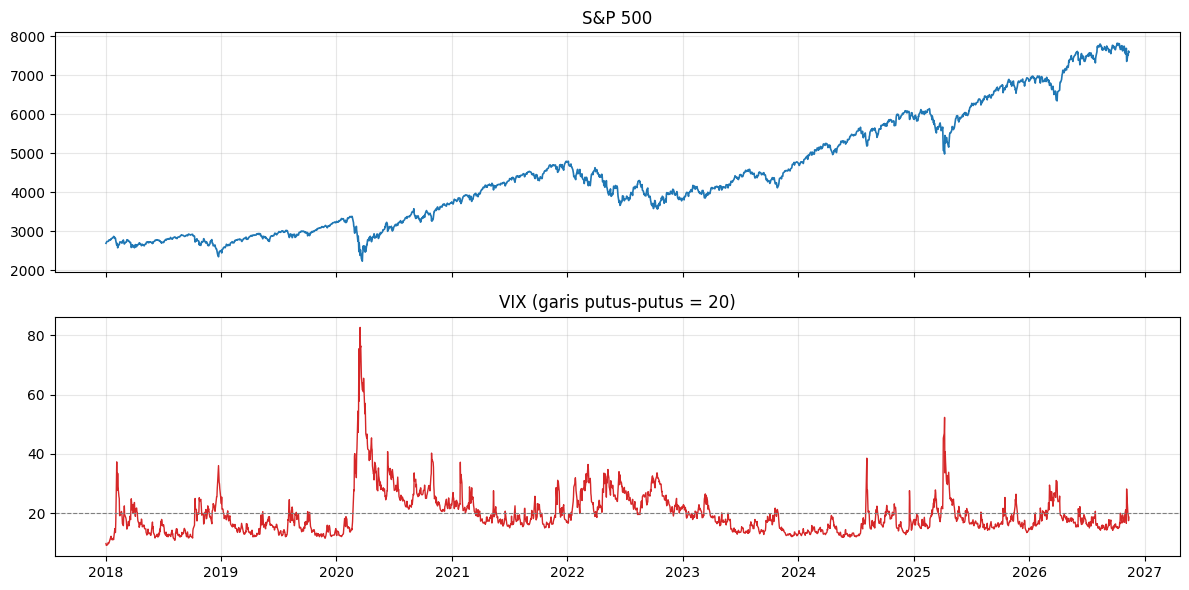

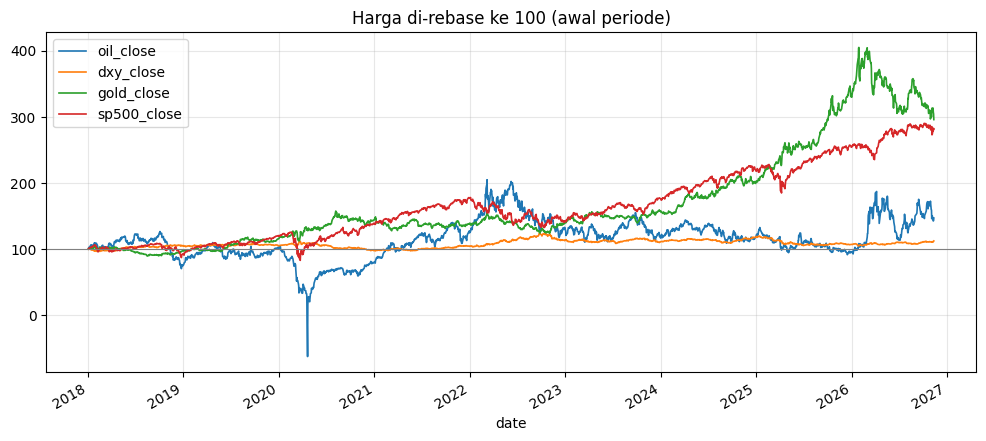

In [ ]:
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].plot(aligned.index, aligned['sp500_close'], lw=1.2)
ax[0].set_title('S&P 500')
ax[1].plot(aligned.index, aligned['vix_close'], color='tab:red', lw=1)
ax[1].axhline(20, ls='--', c='gray', lw=0.8)
ax[1].set_title('VIX (garis putus-putus = 20)')
plt.tight_layout(); plt.show()

cols = [c for c in price_cols if c != 'vix_close']
rb = aligned[cols].apply(lambda s: s / s.dropna().iloc[0] * 100)
ax = rb.plot(figsize=(12, 5), lw=1.2, title='Harga di-rebase ke 100 (awal periode)')
ax.axhline(100, c='gray', lw=0.8); plt.show()

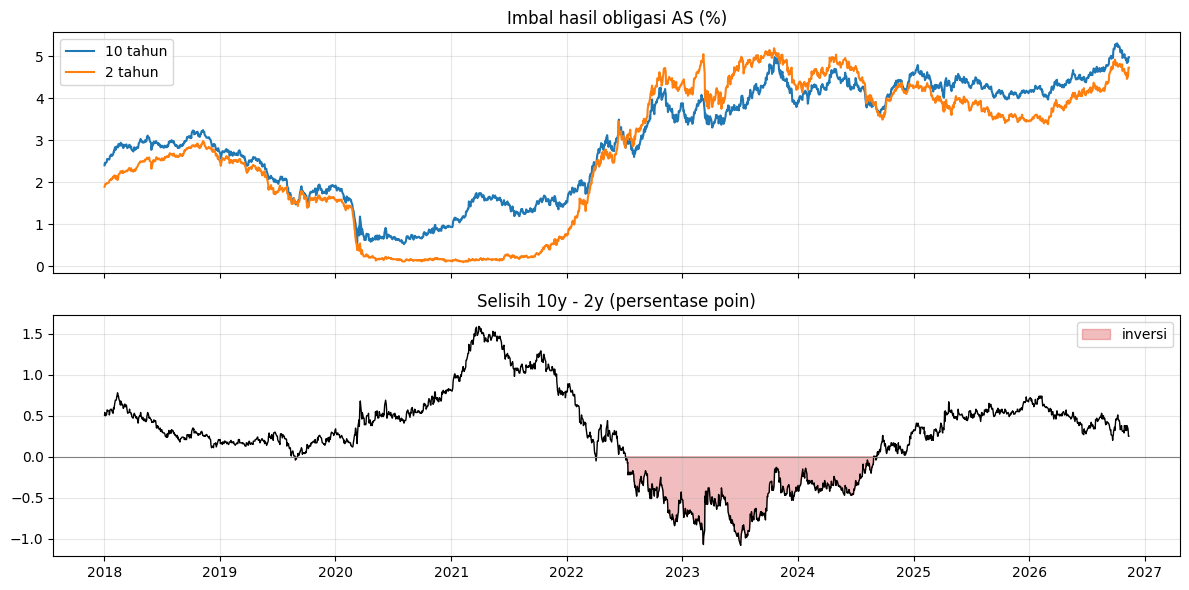

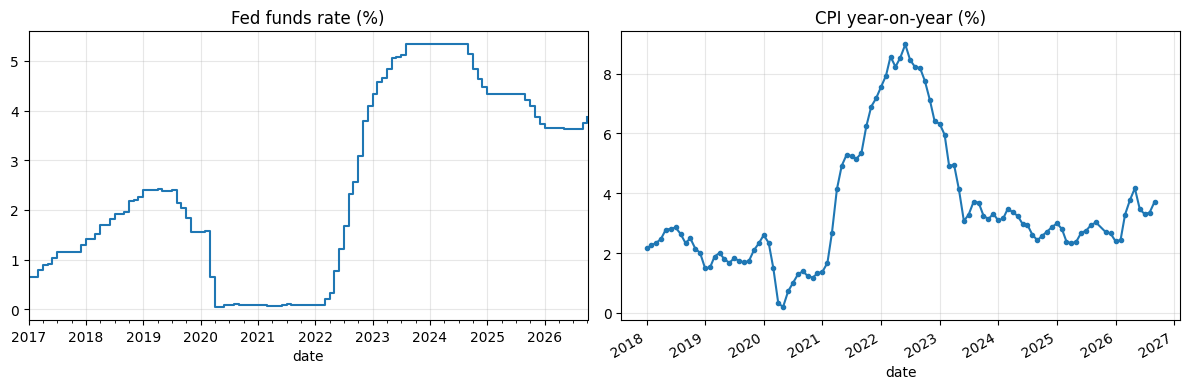

In [ ]:
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].plot(aligned.index, aligned['yield_10y'], label='10 tahun')
ax[0].plot(aligned.index, aligned['yield_2y'], label='2 tahun')
ax[0].set_title('Imbal hasil obligasi AS (%)'); ax[0].legend()
sp = aligned['yield_spread']
ax[1].plot(aligned.index, sp, c='k', lw=1)
ax[1].fill_between(aligned.index, sp, 0, where=sp < 0, color='tab:red', alpha=0.3, label='inversi')
ax[1].axhline(0, c='gray', lw=0.8)
ax[1].set_title('Selisih 10y - 2y (persentase poin)'); ax[1].legend()
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ff.plot(ax=ax[0], drawstyle='steps-post'); ax[0].set_title('Fed funds rate (%)')
cpi_yoy.plot(ax=ax[1], marker='o', ms=3); ax[1].set_title('CPI year-on-year (%)')
plt.tight_layout(); plt.show()

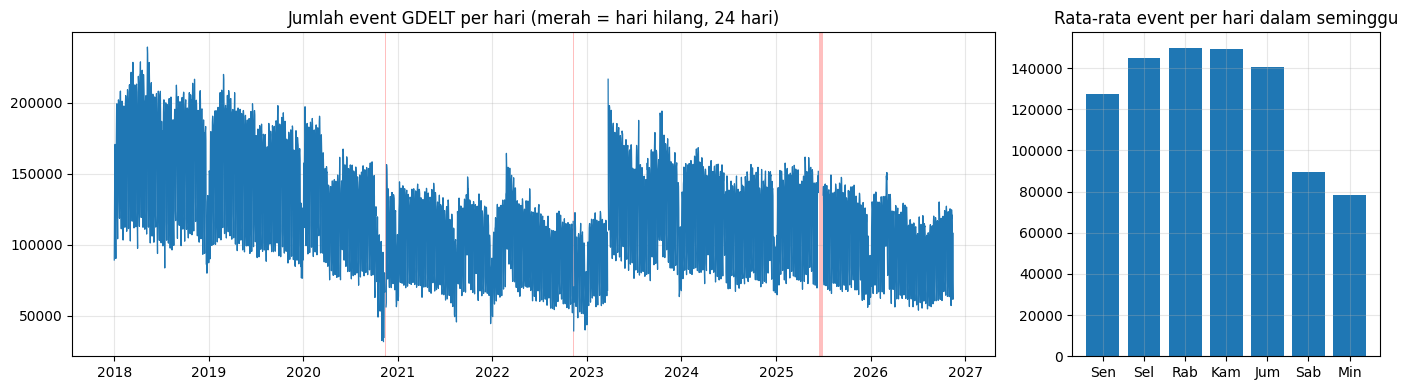

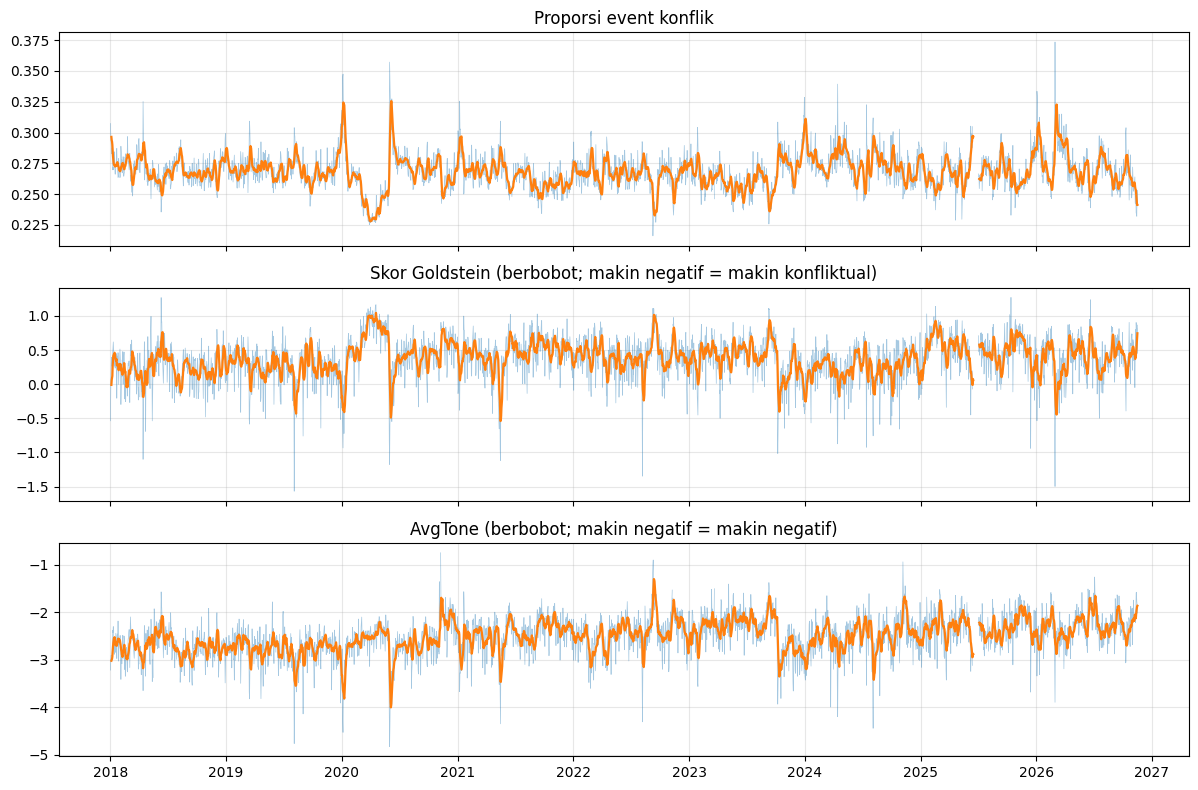

In [ ]:
miss = g.index[g['n_events'].isna()]
fig, ax = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={'width_ratios': [3, 1]})
ax[0].plot(g.index, g['n_events'], lw=0.9)
for d in miss:
    ax[0].axvspan(d, d + pd.Timedelta(days=1), color='red', alpha=0.25, lw=0)
ax[0].set_title(f'Jumlah event GDELT per hari (merah = hari hilang, {len(miss)} hari)')
wk = g['n_events'].groupby(g.index.dayofweek).mean().reindex(range(7))
ax[1].bar(['Sen', 'Sel', 'Rab', 'Kam', 'Jum', 'Sab', 'Min'], wk.values)
ax[1].set_title('Rata-rata event per hari dalam seminggu')
plt.tight_layout(); plt.show()

sig = [('conflict_share', 'Proporsi event konflik'),
       ('goldstein_wmean', 'Skor Goldstein (berbobot; makin negatif = makin konfliktual)'),
       ('avgtone_wmean', 'AvgTone (berbobot; makin negatif = makin negatif)')]
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for ax, (c, t) in zip(axes, sig):
    ax.plot(g.index, g[c], lw=0.5, alpha=0.4)
    ax.plot(g.index, g[c].rolling(7, min_periods=4).mean(), lw=1.6)
    ax.set_title(t)
plt.tight_layout(); plt.show()

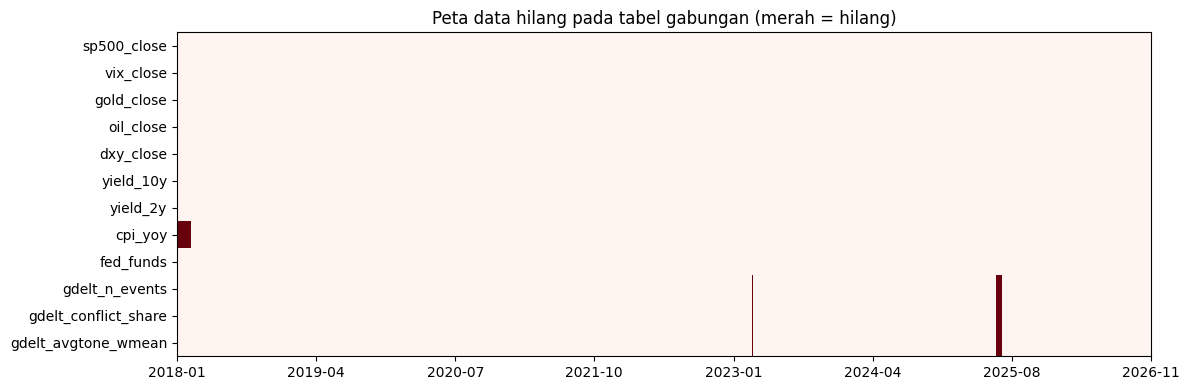

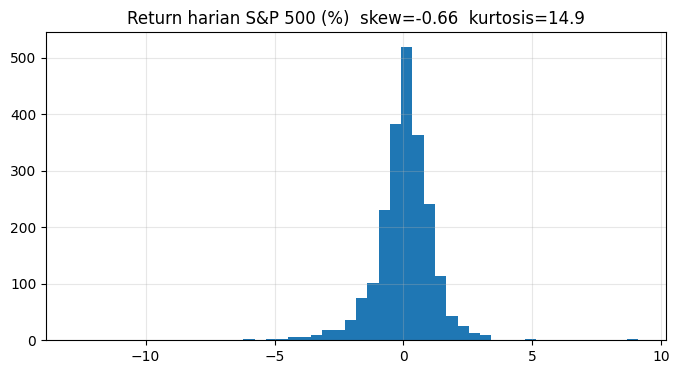

5 hari terburuk:
date
2020-03-16   -12.77
2020-03-12    -9.99
2020-03-09    -7.90
2025-04-04    -6.16
2020-06-11    -6.08


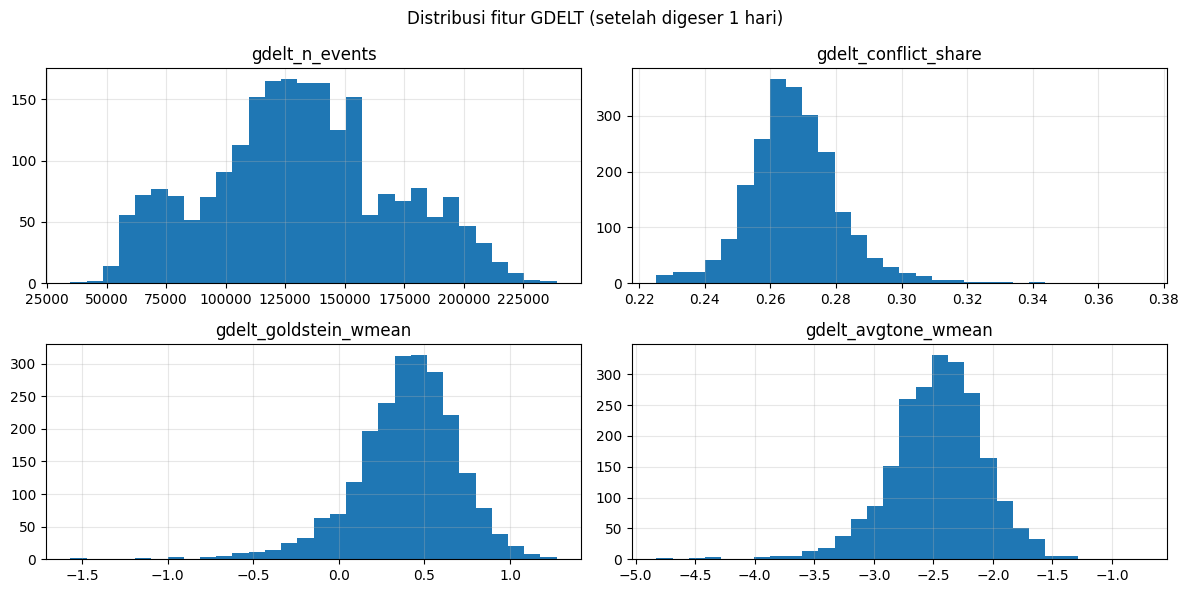

In [ ]:
show = ['sp500_close', 'vix_close', 'gold_close', 'oil_close', 'dxy_close', 'yield_10y', 'yield_2y',
        'cpi_yoy', 'fed_funds', 'gdelt_n_events', 'gdelt_conflict_share', 'gdelt_avgtone_wmean']
na = aligned[show].isna().T.astype(int)
fig, ax = plt.subplots(figsize=(12, 4))
ax.imshow(na.values, aspect='auto', cmap='Reds', interpolation='nearest')
ax.set_yticks(range(len(show))); ax.set_yticklabels(show)
ticks = np.linspace(0, len(aligned) - 1, 8).astype(int)
ax.set_xticks(ticks); ax.set_xticklabels(aligned.index[ticks].strftime('%Y-%m'))
ax.grid(False); ax.set_title('Peta data hilang pada tabel gabungan (merah = hilang)')
plt.tight_layout(); plt.show()

r = aligned['sp500_ret'].dropna()
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(r * 100, bins=50)
ax.set_title(f'Return harian S&P 500 (%)  skew={r.skew():.2f}  kurtosis={r.kurt():.1f}')
plt.show()
print('5 hari terburuk:'); print((r.nsmallest(5) * 100).round(2).to_string())

gcols = ['gdelt_n_events', 'gdelt_conflict_share', 'gdelt_goldstein_wmean', 'gdelt_avgtone_wmean']
aligned[gcols].hist(bins=30, figsize=(12, 6), layout=(2, 2))
plt.suptitle('Distribusi fitur GDELT (setelah digeser 1 hari)'); plt.tight_layout(); plt.show()

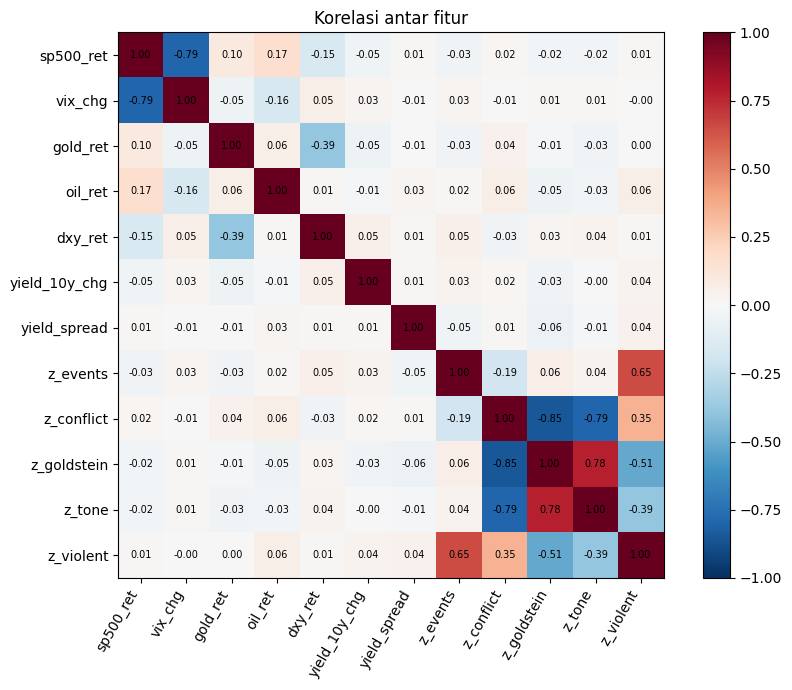

In [ ]:
feat = ['sp500_ret', 'vix_chg', 'gold_ret', 'oil_ret', 'dxy_ret', 'yield_10y_chg', 'yield_spread',
        'z_events', 'z_conflict', 'z_goldstein', 'z_tone', 'z_violent']
corr = aligned[feat].corr()
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(feat))); ax.set_xticklabels(feat, rotation=60, ha='right')
ax.set_yticks(range(len(feat))); ax.set_yticklabels(feat)
for i in range(len(feat)):
    for j in range(len(feat)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=7)
fig.colorbar(im, ax=ax); ax.grid(False); ax.set_title('Korelasi antar fitur')
plt.tight_layout(); plt.show()

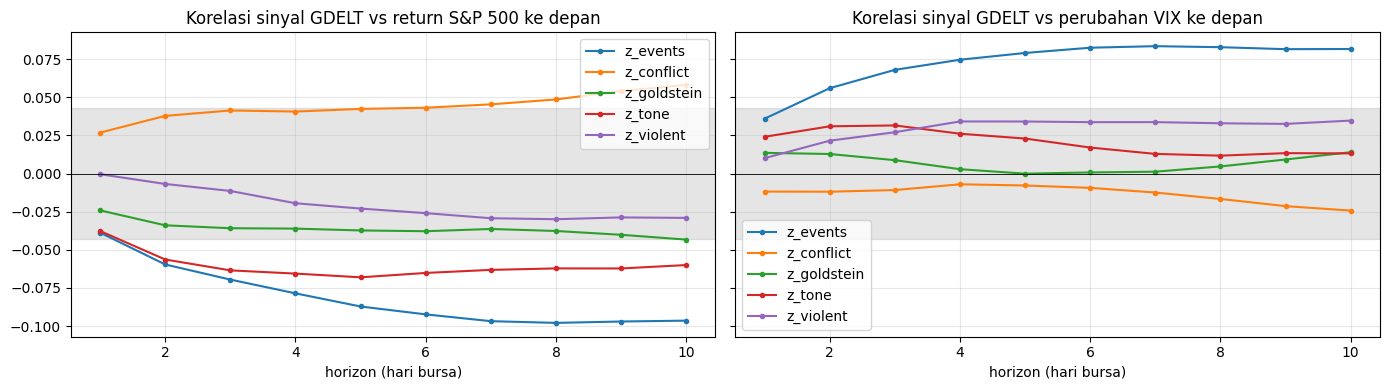

In [ ]:
horizons = range(1, 11)
lr = np.log(aligned['sp500_close'])
fwd_ret = {h: lr.shift(-h) - lr for h in horizons}
fwd_vix = {h: aligned['vix_close'].shift(-h) - aligned['vix_close'] for h in horizons}
zc = ['z_events', 'z_conflict', 'z_goldstein', 'z_tone', 'z_violent']

res_ret = pd.DataFrame({c: [aligned[c].corr(fwd_ret[h]) for h in horizons] for c in zc}, index=list(horizons))
res_vix = pd.DataFrame({c: [aligned[c].corr(fwd_vix[h]) for h in horizons] for c in zc}, index=list(horizons))
band = 2 / np.sqrt(aligned[zc].dropna().shape[0])

fig, ax = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for a, df, t in [(ax[0], res_ret, 'vs return S&P 500 ke depan'), (ax[1], res_vix, 'vs perubahan VIX ke depan')]:
    df.plot(ax=a, marker='o', ms=3)
    a.axhspan(-band, band, color='gray', alpha=0.2)
    a.axhline(0, c='k', lw=0.6)
    a.set_xlabel('horizon (hari bursa)'); a.set_title(f'Korelasi sinyal GDELT {t}')
plt.tight_layout(); plt.show()

In [ ]:
rng = np.random.default_rng(0)

def block_perm(x, y, method='pearson', block=20, n_perm=2000):
    d = pd.concat([x, y], axis=1).dropna()
    if method == 'spearman':
        d = d.rank()
    xv, yv = d.iloc[:, 0].to_numpy(), d.iloc[:, 1].to_numpy()
    obs = np.corrcoef(xv, yv)[0, 1]
    nb = int(np.ceil(len(xv) / block))
    blocks = [xv[i * block:(i + 1) * block] for i in range(nb)]
    null = np.empty(n_perm)
    for k in range(n_perm):
        xp = np.concatenate([blocks[i] for i in rng.permutation(nb)])
        null[k] = np.corrcoef(xp, yv)[0, 1]
    return obs, float((np.abs(null) >= abs(obs)).mean()), len(xv)
idx = aligned.index.to_series()
krisis = (idx.between('2020-02-15', '2020-05-31') | idx.between('2025-03-15', '2025-05-31')).to_numpy()
print(f'Hari yang dibuang pada uji "tanpa krisis": {int(krisis.sum())} dari {len(krisis)}')

rows = []
for c in ['z_events', 'z_tone', 'z_conflict']:
    for h in [5, 10]:
        y = fwd_ret[h]
        for method in ['pearson', 'spearman']:
            r1, p1, n1 = block_perm(aligned[c], y, method)
            r2, p2, n2 = block_perm(aligned[c][~krisis], y[~krisis], method)
            rows.append({'fitur': c, 'horizon': h, 'metode': method,
                         'r semua': round(r1, 3), 'p semua': round(p1, 3),
                         'r tanpa krisis': round(r2, 3), 'p tanpa krisis': round(p2, 3),
                         'N baris': n1, 'N independen kasar': n1 // h})
display(pd.DataFrame(rows))

Hari yang dibuang pada uji "tanpa krisis": 125 dari 2229


,fitur,horizon,metode,r semua,p semua,r tanpa krisis,p tanpa krisis,N baris,N independen kasar
0,z_events,5,pearson,-0.087,0.031,-0.050,0.251,2164,432
1,z_events,5,spearman,-0.089,0.029,-0.062,0.144,2164,432
2,z_events,10,pearson,-0.096,0.074,-0.053,0.322,2159,215
3,z_events,10,spearman,-0.114,0.036,-0.078,0.162,2159,215
4,z_tone,5,pearson,-0.068,0.112,-0.073,0.089,2164,432
5,z_tone,5,spearman,-0.038,0.339,-0.040,0.316,2164,432
6,z_tone,10,pearson,-0.060,0.241,-0.075,0.150,2159,215
7,z_tone,10,spearman,-0.035,0.500,-0.049,0.344,2159,215
8,z_conflict,5,pearson,0.042,0.322,0.030,0.459,2164,432
9,z_conflict,5,spearman,0.030,0.465,0.020,0.625,2164,432


In [ ]:
lr_close = aligned['sp500_close']
fwd_min = pd.concat([lr_close.shift(-h) for h in range(1, 6)], axis=1).min(axis=1)
dd5 = fwd_min / lr_close - 1
dd5 = dd5.iloc[:-5]
for th in [0.02, 0.03, 0.04, 0.05]:
    flag = dd5 <= -th
    episodes = int((flag & ~flag.shift(1, fill_value=False)).sum())
    print(f'drawdown 5 hari >= {th:.0%}: {flag.sum():4d} hari ({flag.mean():.1%}), {episodes} episode terpisah')

drawdown 5 hari >= 2%:  459 hari (20.6%), 133 episode terpisah
drawdown 5 hari >= 3%:  242 hari (10.9%), 81 episode terpisah
drawdown 5 hari >= 4%:  132 hari (5.9%), 49 episode terpisah
drawdown 5 hari >= 5%:   80 hari (3.6%), 28 episode terpisah


In [ ]:
HORIZON = 5
THRESHOLDS = {'shock3': 0.03, 'shock4': 0.04}

close = aligned['sp500_close']
fwd_min = pd.concat([close.shift(-h) for h in range(1, HORIZON + 1)], axis=1).min(axis=1, skipna=False)
dd5 = fwd_min / close - 1

y = pd.DataFrame({'dd5': dd5})
for name, th in THRESHOLDS.items():
    y[name] = np.where(dd5.notna(), (dd5 <= -th).astype(float), np.nan)

def count_episodes(flag):
    flag = flag.astype(bool)
    return int((flag & ~flag.shift(1, fill_value=False)).sum())

for name in THRESHOLDS:
    f = y[name].dropna() == 1
    print(f'{name}: {int(f.sum())} hari shock ({f.mean():.1%}), {count_episodes(f)} episode terpisah')

shock3: 242 hari shock (10.9%), 81 episode terpisah
shock4: 132 hari shock (5.9%), 49 episode terpisah


In [ ]:

def build_market_features(df):
    out = pd.DataFrame(index=df.index)
    lr = np.log(df['sp500_close'])
    r1 = lr.diff()
    out['ret_1'] = r1
    out['ret_5'] = lr - lr.shift(5)
    out['ret_20'] = lr - lr.shift(20)
    out['vol_10'] = r1.rolling(10).std() * np.sqrt(252)
    out['vol_60'] = r1.rolling(60).std() * np.sqrt(252)
    out['vol_ratio'] = out['vol_10'] / out['vol_60']
    out['dd_60'] = df['sp500_close'] / df['sp500_close'].rolling(60).max() - 1
    out['vix'] = df['vix_close']
    out['vix_chg_5'] = df['vix_close'] - df['vix_close'].shift(5)
    out['vix_vs_ma20'] = df['vix_close'] / df['vix_close'].rolling(20).mean() - 1
    for a in ['gold', 'oil', 'dxy']:
        px = df[f'{a}_close'].where(df[f'{a}_close'] > 0)
        out[f'{a}_ret_5'] = np.log(px) - np.log(px).shift(5)
    out['yield_spread'] = df['yield_10y'] - df['yield_2y']
    out['yield_10y_chg_20'] = df['yield_10y'] - df['yield_10y'].shift(20)
    out['fed_funds'] = df['fed_funds']
    out['cpi_yoy'] = df['cpi_yoy']
    return out

GDELT_FEATURES = ['z_events', 'z_conflict', 'z_goldstein', 'z_tone', 'z_violent']

mf = build_market_features(aligned)
MARKET_FEATURES = list(mf.columns)

rng = np.random.default_rng(1)
cands = mf.dropna().index[100:-10]
bad = 0
for t in rng.choice(cands, size=8, replace=False):
    t = pd.Timestamp(t)
    trunc = build_market_features(aligned.loc[:t]).loc[t].to_numpy(dtype=float)
    full = mf.loc[t].to_numpy(dtype=float)
    if not np.allclose(trunc, full, equal_nan=True):
        bad += 1
        print('BEDA di', t.date())
print('Uji anti-bocor:', 'LULUS' if bad == 0 else f'GAGAL di {bad} tanggal')
assert bad == 0, 'Ada kebocoran informasi masa depan di fitur. Hentikan dan periksa.'

Uji anti-bocor: LULUS


In [ ]:
# ---------- Rakit dataset model ----------
data = pd.concat([y, mf, aligned[GDELT_FEATURES], aligned[['gdelt_missing']]], axis=1)
n0 = len(data)
data = data.dropna(subset=['shock3'])
n1 = len(data)
data = data.dropna(subset=MARKET_FEATURES)
n2 = len(data)
data = data.dropna(subset=GDELT_FEATURES)
n3 = len(data)
print(f'Baris awal {n0} | tanpa target (5 hari terakhir) -{n0 - n1} | warm-up fitur pasar/makro -{n1 - n2} '
      f'| GDELT kosong -{n2 - n3} | tersisa {n3}')
print(f'Periode: {data.index.min().date()} -> {data.index.max().date()}')
print('Model dengan dan tanpa GDELT dievaluasi pada baris yang SAMA agar perbandingannya adil.')

for name in THRESHOLDS:
    f = data[name] == 1
    print(f'{name}: base rate {f.mean():.1%}, {int(f.sum())} hari, {count_episodes(f)} episode')

os.makedirs(f'{BASE}/processed', exist_ok=True)
data.reset_index().to_parquet(f'{BASE}/processed/features.parquet', index=False)
print('Tersimpan: processed/features.parquet', data.shape)

Baris awal 2229 | tanpa target (5 hari terakhir) -5 | warm-up fitur pasar/makro -62 | GDELT kosong -17 | tersisa 2145
Periode: 2018-03-29 -> 2026-11-05
Model dengan dan tanpa GDELT dievaluasi pada baris yang SAMA agar perbandingannya adil.
shock3: base rate 10.6%, 227 hari, 77 episode
shock4: base rate 5.7%, 122 hari, 46 episode
Tersimpan: processed/features.parquet (2145, 26)


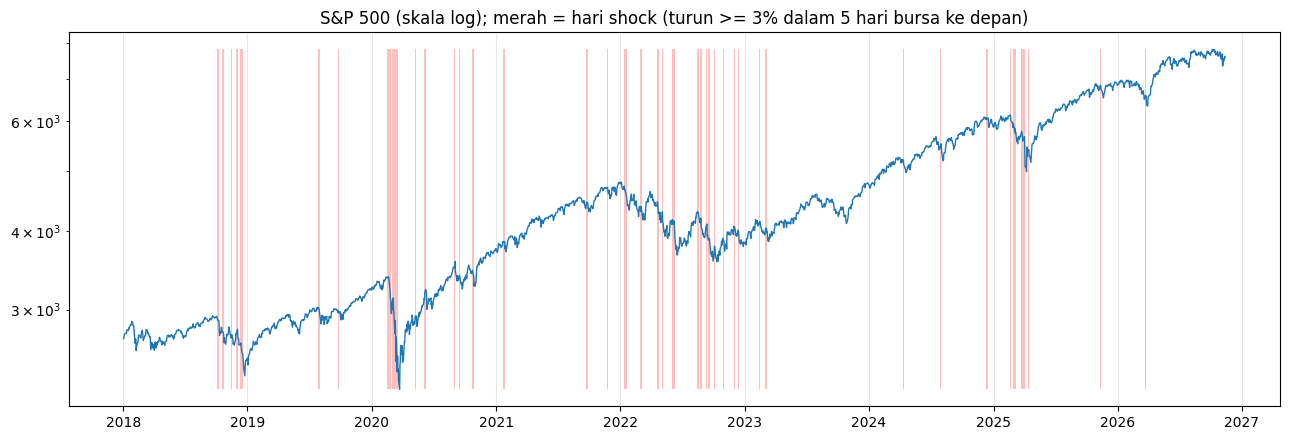

,hari,hari_shock,episode,persen
date,,,,
2018,191,26,6,13.6
2019,252,9,4,3.6
2020,246,51,14,20.7
2021,252,13,7,5.2
2022,251,71,22,28.3
2023,250,13,7,5.2
2024,252,14,5,5.6
2025,238,22,7,9.2
2026,213,8,5,3.8


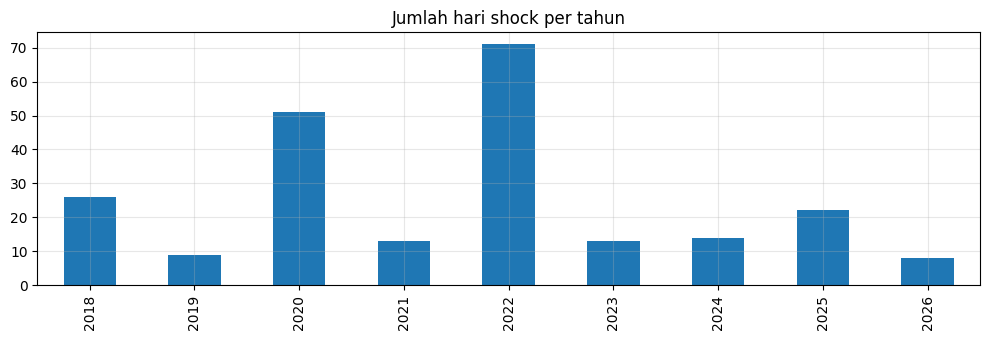

In [ ]:
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(aligned.index, aligned['sp500_close'], lw=1)
ax.set_yscale('log')
lo, hi = aligned['sp500_close'].min(), aligned['sp500_close'].max()
ax.fill_between(data.index, lo, hi, where=(data['shock3'] == 1).to_numpy(), color='red', alpha=0.25, linewidth=0)
ax.set_title('S&P 500 (skala log); merah = hari shock (turun >= 3% dalam 5 hari bursa ke depan)')
plt.tight_layout(); plt.show()

s = data['shock3'] == 1
yr = pd.DataFrame({
    'hari': data.groupby(data.index.year).size(),
    'hari_shock': s.groupby(data.index.year).sum().astype(int),
    'episode': s.groupby(data.index.year).apply(count_episodes),
})
yr['persen'] = (yr['hari_shock'] / yr['hari'] * 100).round(1)
display(yr)
ax = yr['hari_shock'].plot.bar(figsize=(10, 3.5), title='Jumlah hari shock per tahun')
ax.set_xlabel('')
plt.tight_layout(); plt.show()

In [ ]:
from sklearn.metrics import roc_auc_score

rows = []
for c in MARKET_FEATURES + GDELT_FEATURES:
    auc = roc_auc_score(data['shock3'], data[c])
    rows.append({'fitur': c, 'kelompok': 'GDELT' if c in GDELT_FEATURES else 'pasar/makro',
                 'AUC': round(auc, 3), 'arah': '+' if auc >= 0.5 else '-',
                 'kekuatan': round(abs(auc - 0.5), 3)})
auc_tbl = pd.DataFrame(rows).sort_values('kekuatan', ascending=False).reset_index(drop=True)
display(auc_tbl)
print(f"Base rate shock3 = {data['shock3'].mean():.1%}  (ini juga nilai PR-AUC untuk tebakan acak)")

,fitur,kelompok,AUC,arah,kekuatan
0,vix,pasar/makro,0.719,+,0.219
1,dd_60,pasar/makro,0.292,-,0.208
2,vol_10,pasar/makro,0.696,+,0.196
3,vol_60,pasar/makro,0.654,+,0.154
4,ret_20,pasar/makro,0.356,-,0.144
5,vix_vs_ma20,pasar/makro,0.633,+,0.133
6,vol_ratio,pasar/makro,0.622,+,0.122
7,fed_funds,pasar/makro,0.392,-,0.108
8,ret_5,pasar/makro,0.426,-,0.074
9,cpi_yoy,pasar/makro,0.566,+,0.066


Base rate shock3 = 10.6%  (ini juga nilai PR-AUC untuk tebakan acak)


2145 baris | 6 fold | gap 10 hari
fold 1: train 2018-03-29 -> 2020-09-21 (623) | test 2020-10-06 -> 2021-10-12 (252), shock3 di test: 15 hari
fold 2: train 2018-03-29 -> 2021-09-28 (875) | test 2021-10-13 -> 2022-10-12 (252), shock3 di test: 66 hari
fold 3: train 2018-03-29 -> 2022-09-28 (1127) | test 2022-10-13 -> 2023-10-13 (252), shock3 di test: 18 hari
fold 4: train 2018-03-29 -> 2023-09-29 (1379) | test 2023-10-16 -> 2024-10-15 (252), shock3 di test: 13 hari
fold 5: train 2018-03-29 -> 2024-10-01 (1631) | test 2024-10-16 -> 2025-11-04 (252), shock3 di test: 25 hari
fold 6: train 2018-03-29 -> 2025-10-21 (1883) | test 2025-11-05 -> 2026-11-05 (252), shock3 di test: 10 hari


,BIC,AIC
K,,
2,3817.5,3688.9
3,3135.1,2939.9
4,3074.2,2812.6
5,2832.7,2504.5


K terpilih (BIC minimum): 5


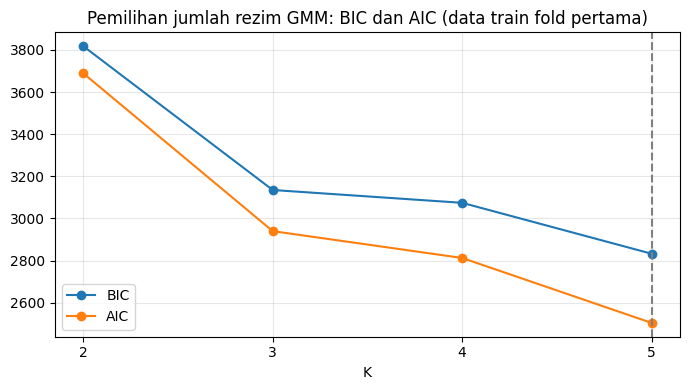

In [ ]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler


GAP, TEST_SIZE = 10, 252
n = len(data)
n_splits = int(min(6, (n - 500) // TEST_SIZE))
assert n_splits >= 3, 'Data terlalu pendek untuk validasi berurutan'
splits = list(TimeSeriesSplit(n_splits=n_splits, test_size=TEST_SIZE, gap=GAP).split(data))

print(f'{n} baris | {n_splits} fold | gap {GAP} hari')
for k, (tr, te) in enumerate(splits, 1):
    print(f'fold {k}: train {data.index[tr[0]].date()} -> {data.index[tr[-1]].date()} ({len(tr)}) | '
          f'test {data.index[te[0]].date()} -> {data.index[te[-1]].date()} ({len(te)}), '
          f"shock3 di test: {int(data['shock3'].iloc[te].sum())} hari")


def regime_matrix(df):
    return np.column_stack([np.log(df['vix']), np.log(df['vol_10'].clip(lower=1e-4)),
                            df['dd_60'], df['ret_20']])

def fit_regime(train_df, K):
    sc = StandardScaler().fit(regime_matrix(train_df))
    gm = GaussianMixture(K, covariance_type='full', n_init=5, reg_covar=1e-4, random_state=0)
    gm.fit(sc.transform(regime_matrix(train_df)))
    order = np.argsort(gm.means_[:, 0])
    return lambda df: gm.predict_proba(sc.transform(regime_matrix(df)))[:, order]

first_train = data.iloc[splits[0][0]]
Xs = StandardScaler().fit_transform(regime_matrix(first_train))
ic = []
for K in range(2, 6):
    gm = GaussianMixture(K, covariance_type='full', n_init=5, reg_covar=1e-4, random_state=0).fit(Xs)
    ic.append({'K': K, 'BIC': gm.bic(Xs), 'AIC': gm.aic(Xs)})
ic = pd.DataFrame(ic).set_index('K')
K_REGIME = int(ic['BIC'].idxmin())
display(ic.round(1))
print('K terpilih (BIC minimum):', K_REGIME)

fig, ax = plt.subplots(figsize=(7, 4))
ic.plot(ax=ax, marker='o')
ax.axvline(K_REGIME, ls='--', c='gray')
ax.set_xticks(ic.index)
ax.set_title('Pemilihan jumlah rezim GMM: BIC dan AIC (data train fold pertama)')
plt.tight_layout(); plt.show()

,hari,persen_hari,vix_rata2,vol_10_rata2,ret_5_rata2_%,shock3_%
rezim (0 = paling tenang),,,,,,
0,511,23.8,14.5,0.095,1.35,2.7
1,608,28.3,17.5,0.103,0.35,7.6
2,504,23.5,19.6,0.164,-0.43,10.3
3,481,22.4,25.3,0.236,-0.30,21.0
4,41,1.9,49.8,0.660,-0.81,34.1


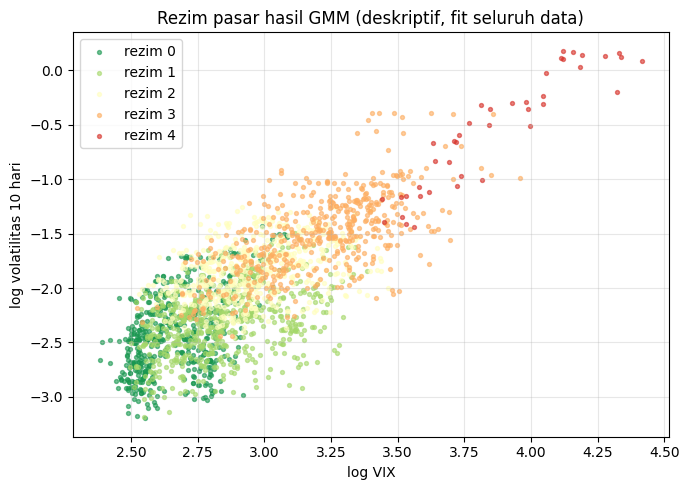

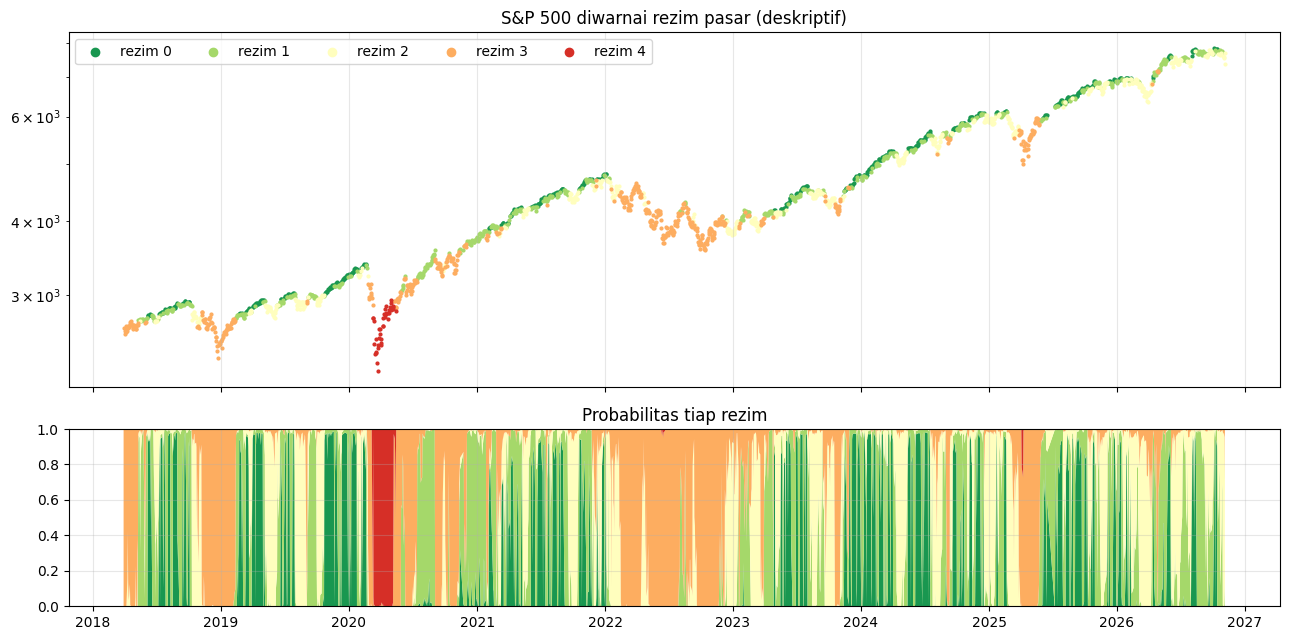

In [ ]:
proba_full = fit_regime(data, K_REGIME)
reg = pd.DataFrame(proba_full(data), index=data.index, columns=[f'p_reg_{i}' for i in range(K_REGIME)])
label = reg.idxmax(axis=1).str[-1].astype(int)

summ = pd.DataFrame({
    'hari': label.value_counts().sort_index(),
    'persen_hari': (label.value_counts(normalize=True).sort_index() * 100).round(1),
    'vix_rata2': data.groupby(label)['vix'].mean().round(1),
    'vol_10_rata2': data.groupby(label)['vol_10'].mean().round(3),
    'ret_5_rata2_%': (data.groupby(label)['ret_5'].mean() * 100).round(2),
    'shock3_%': (data.groupby(label)['shock3'].mean() * 100).round(1),
})
summ.index.name = 'rezim (0 = paling tenang)'
display(summ)

colors = plt.cm.RdYlGn_r(np.linspace(0.1, 0.9, K_REGIME))

fig, ax = plt.subplots(figsize=(7, 5))
for k in range(K_REGIME):
    mk = (label == k).to_numpy()
    ax.scatter(np.log(data.loc[mk, 'vix']), np.log(data.loc[mk, 'vol_10']), s=8, color=colors[k],
               alpha=0.6, label=f'rezim {k}')
ax.set_xlabel('log VIX'); ax.set_ylabel('log volatilitas 10 hari'); ax.legend()
ax.set_title('Rezim pasar hasil GMM (deskriptif, fit seluruh data)')
plt.tight_layout(); plt.show()

# Chart 15
fig, ax = plt.subplots(2, 1, figsize=(13, 6.5), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
px = aligned['sp500_close'].reindex(data.index)
for k in range(K_REGIME):
    mk = (label == k).to_numpy()
    ax[0].scatter(data.index[mk], px[mk], s=4, color=colors[k], label=f'rezim {k}')
ax[0].set_yscale('log'); ax[0].legend(markerscale=3, ncol=K_REGIME)
ax[0].set_title('S&P 500 diwarnai rezim pasar (deskriptif)')
ax[1].stackplot(data.index, reg.to_numpy().T, colors=colors)
ax[1].set_ylim(0, 1); ax[1].set_title('Probabilitas tiap rezim')
plt.tight_layout(); plt.show()

In [ ]:
import time, warnings
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, brier_score_loss
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)

def make_lr():   return make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=2000))
def make_rf():   return RandomForestClassifier(n_estimators=200, min_samples_leaf=20, max_features='sqrt',
                                               n_jobs=-1, random_state=0)
def make_lgbm(): return LGBMClassifier(n_estimators=200, learning_rate=0.03, num_leaves=8, min_child_samples=30,
                                       subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=5.0,
                                       random_state=0, verbose=-1)
def make_cat():  return CatBoostClassifier(iterations=300, depth=4, learning_rate=0.03, l2_leaf_reg=5,
                                           random_seed=0, verbose=0)
BASE_MODELS = [make_rf, make_lgbm, make_cat]

def _logit(p):
    p = np.clip(p, 1e-4, 1 - 1e-4)
    return np.log(p / (1 - p))

def fit_predict_lr(Xtr, ytr, Xte):
    return make_lr().fit(Xtr, ytr).predict_proba(Xte)[:, 1]

def fit_predict_stack(Xtr, ytr, Xte, n_inner=4):
    """Stacking: RF + LightGBM + CatBoost -> meta-learner LogReg.
    Prediksi base model untuk melatih meta-learner dibuat dengan validasi berurutan DI DALAM data train
    (tidak ada data test yang ikut)."""
    inner = TimeSeriesSplit(n_splits=n_inner, gap=GAP)
    oof = np.full((len(Xtr), len(BASE_MODELS)), np.nan)
    for a, b in inner.split(Xtr):
        if ytr[a].sum() == 0 or ytr[a].sum() == len(a):
            continue
        for j, make in enumerate(BASE_MODELS):
            oof[b, j] = make().fit(Xtr[a], ytr[a]).predict_proba(Xtr[b])[:, 1]
    ok = ~np.isnan(oof).any(axis=1)
    te = np.column_stack([make().fit(Xtr, ytr).predict_proba(Xte)[:, 1] for make in BASE_MODELS])
    if ok.sum() < 100 or ytr[ok].sum() < 10:      # terlalu sedikit untuk melatih meta-learner: rata-rata biasa
        return te.mean(axis=1)
    meta = LogisticRegression(C=1.0, max_iter=1000).fit(_logit(oof[ok]), ytr[ok])
    return meta.predict_proba(_logit(te))[:, 1]

def run_walk_forward(target):
    """Latih dan prediksi per fold. Semua transformasi (scaler, GMM) hanya dipasang pada data train fold."""
    parts = []
    for k, (tr_idx, te_idx) in enumerate(splits, 1):
        t0 = time.time()
        tr, te = data.iloc[tr_idx], data.iloc[te_idx]
        ytr, yte = tr[target].to_numpy(int), te[target].to_numpy(int)
        proba = fit_regime(tr, K_REGIME)
        Mtr = np.column_stack([tr[MARKET_FEATURES].to_numpy(float), proba(tr)])
        Mte = np.column_stack([te[MARKET_FEATURES].to_numpy(float), proba(te)])
        Gtr, Gte = tr[GDELT_FEATURES].to_numpy(float), te[GDELT_FEATURES].to_numpy(float)
        sets = {'tanpa GDELT': (Mtr, Mte), 'dengan GDELT': (np.hstack([Mtr, Gtr]), np.hstack([Mte, Gte]))}

        out = pd.DataFrame({'fold': k, 'y': yte}, index=te.index)
        out['Base rate'] = ytr.mean()
        for sname, (Xtr, Xte) in sets.items():
            out[f'LogReg {sname}'] = fit_predict_lr(Xtr, ytr, Xte)
            out[f'Stacking {sname}'] = fit_predict_stack(Xtr, ytr, Xte)
        parts.append(out)
        print(f'  [{target}] fold {k}/{len(splits)} selesai ({time.time() - t0:.0f} dtk)')
    return pd.concat(parts)

MODELS = ['Base rate', 'LogReg tanpa GDELT', 'LogReg dengan GDELT', 'Stacking tanpa GDELT', 'Stacking dengan GDELT']
print('Fungsi model siap. Fitur: ', len(MARKET_FEATURES), 'pasar/makro +', K_REGIME, 'probabilitas rezim +',
      len(GDELT_FEATURES), 'GDELT')

Fungsi model siap. Fitur:  17 pasar/makro + 5 probabilitas rezim + 5 GDELT


In [ ]:
t0 = time.time()
oof3 = run_walk_forward('shock3')
print(f'\nSelesai dalam {(time.time() - t0) / 60:.1f} menit | {len(oof3)} prediksi out-of-fold, '
      f"{int(oof3['y'].sum())} hari shock")
oof3.reset_index().to_parquet(f'{BASE}/processed/oof_shock3.parquet', index=False)

  [shock3] fold 1/6 selesai (9 dtk)
  [shock3] fold 2/6 selesai (11 dtk)
  [shock3] fold 3/6 selesai (13 dtk)
  [shock3] fold 4/6 selesai (13 dtk)
  [shock3] fold 5/6 selesai (14 dtk)
  [shock3] fold 6/6 selesai (14 dtk)

Selesai dalam 1.3 menit | 1512 prediksi out-of-fold, 147 hari shock


In [ ]:
from sklearn.metrics import roc_auc_score

def metric_table(oof, models=MODELS):
    rows = []
    for m in models:
        rows.append({'model': m,
                     'PR-AUC': average_precision_score(oof['y'], oof[m]),
                     'ROC-AUC': roc_auc_score(oof['y'], oof[m]),
                     'Brier': brier_score_loss(oof['y'], oof[m])})
    return pd.DataFrame(rows).set_index('model')

tbl3 = metric_table(oof3)
base_rate = oof3['y'].mean()
display(tbl3.round(4))
print(f'Base rate (pooled out-of-fold) = {base_rate:.3f}. PR-AUC tebakan acak kira-kira sebesar ini; '
      f'Brier tebakan konstan = {brier_score_loss(oof3["y"], np.full(len(oof3), base_rate)):.4f}')

,PR-AUC,ROC-AUC,Brier
model,,,
Base rate,0.0804,0.3487,0.0895
LogReg tanpa GDELT,0.1668,0.6725,0.0958
LogReg dengan GDELT,0.1570,0.6629,0.0992
Stacking tanpa GDELT,0.1516,0.6271,0.0919
Stacking dengan GDELT,0.1178,0.5802,0.0927


Base rate (pooled out-of-fold) = 0.097. PR-AUC tebakan acak kira-kira sebesar ini; Brier tebakan konstan = 0.0878


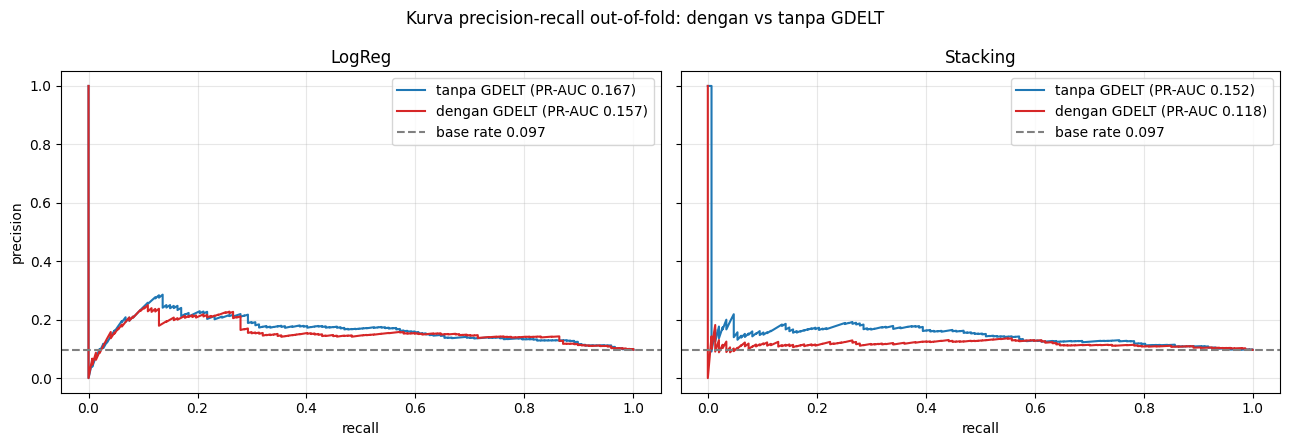

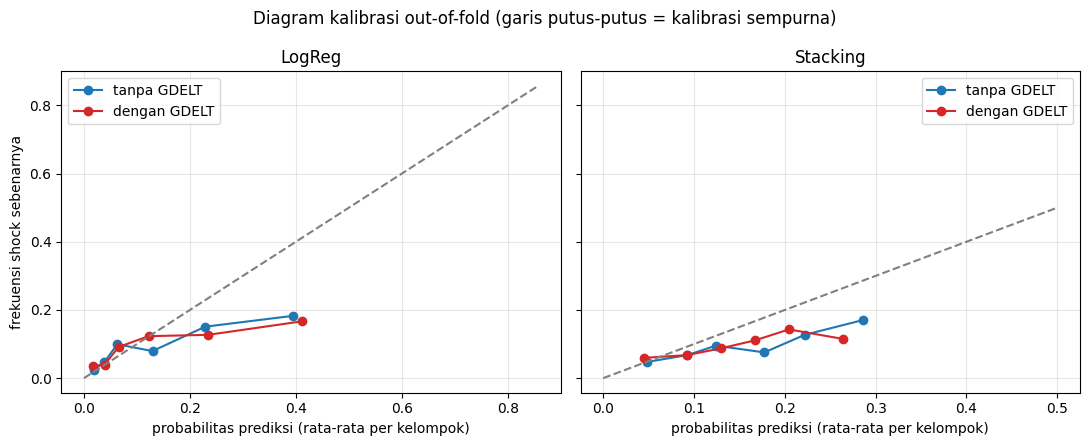

In [ ]:
from sklearn.metrics import precision_recall_curve
from sklearn.calibration import calibration_curve

COL = {'tanpa GDELT': 'tab:blue', 'dengan GDELT': 'tab:red'}

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for a, fam in zip(ax, ['LogReg', 'Stacking']):
    for suf, c in COL.items():
        m = f'{fam} {suf}'
        p, r, _ = precision_recall_curve(oof3['y'], oof3[m])
        a.plot(r, p, color=c, label=f"{suf} (PR-AUC {tbl3.loc[m, 'PR-AUC']:.3f})")
    a.axhline(base_rate, ls='--', c='gray', label=f'base rate {base_rate:.3f}')
    a.set_xlabel('recall'); a.set_title(fam); a.legend()
ax[0].set_ylabel('precision')
fig.suptitle('Kurva precision-recall out-of-fold: dengan vs tanpa GDELT')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for a, fam in zip(ax, ['LogReg', 'Stacking']):
    for suf, c in COL.items():
        frac, mp = calibration_curve(oof3['y'], oof3[f'{fam} {suf}'], n_bins=6, strategy='quantile')
        a.plot(mp, frac, marker='o', color=c, label=suf)
    lim = max(0.5, float(oof3[[f'{fam} {s}' for s in COL]].to_numpy().max()))
    a.plot([0, lim], [0, lim], ls='--', c='gray')
    a.set_xlabel('probabilitas prediksi (rata-rata per kelompok)'); a.set_title(fam); a.legend()
ax[0].set_ylabel('frekuensi shock sebenarnya')
fig.suptitle('Diagram kalibrasi out-of-fold (garis putus-putus = kalibrasi sempurna)')
plt.tight_layout(); plt.show()

,periode,hari shock,base rate,LogReg tanpa GDELT,LogReg dengan GDELT,Stacking tanpa GDELT,Stacking dengan GDELT
fold,,,,,,,
1,2020-10-06 -> 2021-10-12,15,0.060,0.077,0.070,0.079,0.093
2,2021-10-13 -> 2022-10-12,66,0.262,0.342,0.350,0.273,0.269
3,2022-10-13 -> 2023-10-13,18,0.071,0.149,0.160,0.074,0.074
4,2023-10-16 -> 2024-10-15,13,0.052,0.168,0.110,0.134,0.102
5,2024-10-16 -> 2025-11-04,25,0.099,0.246,0.329,0.204,0.199
6,2025-11-05 -> 2026-11-05,10,0.040,0.050,0.051,0.127,0.063


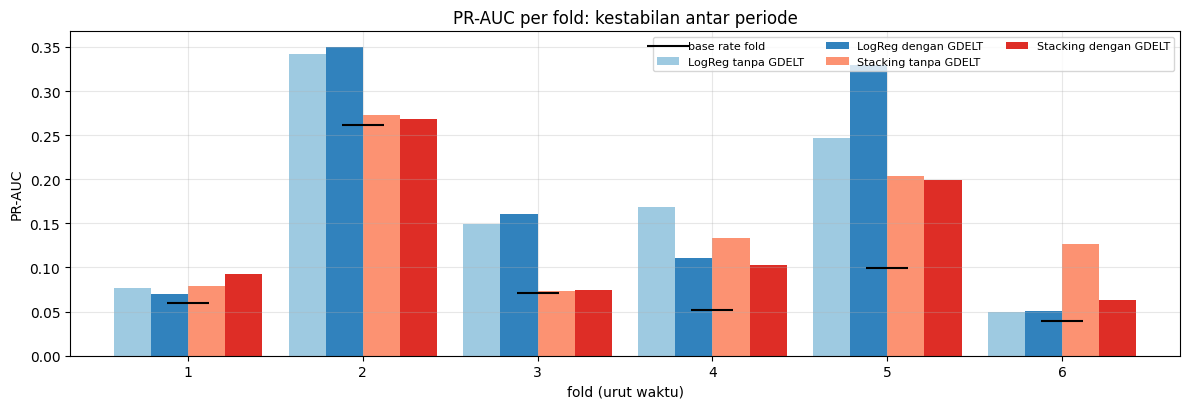

In [ ]:
rows = []
for k, g_ in oof3.groupby('fold'):
    if g_['y'].sum() == 0:
        continue
    r = {'fold': k, 'periode': f"{g_.index.min().date()} -> {g_.index.max().date()}",
         'hari shock': int(g_['y'].sum()), 'base rate': g_['y'].mean()}
    for m in MODELS[1:]:
        r[m] = average_precision_score(g_['y'], g_[m])
    rows.append(r)
pf = pd.DataFrame(rows).set_index('fold')
display(pf.round(3))

ax = pf[MODELS[1:]].plot.bar(figsize=(12, 4.2), width=0.85, rot=0,
                             color=['#9ecae1', '#3182bd', '#fc9272', '#de2d26'])
ax.scatter(range(len(pf)), pf['base rate'], marker='_', s=900, color='k', label='base rate fold', zorder=5)
ax.set_xlabel('fold (urut waktu)'); ax.set_ylabel('PR-AUC'); ax.legend(ncol=3, fontsize=8)
ax.set_title('PR-AUC per fold: kestabilan antar periode')
plt.tight_layout(); plt.show()

selisih  CI95 bawah  CI95 atas  P(selisih>0)
model    metrik                                              
LogReg   PR-AUC  -0.0098     -0.0408     0.0126         0.234
         Brier    0.0035      0.0000     0.0070         0.976
Stacking PR-AUC  -0.0337     -0.0631    -0.0063         0.010
         Brier    0.0008     -0.0016     0.0030         0.754

Catatan: untuk PR-AUC, selisih > 0 = GDELT membantu. Untuk Brier, selisih < 0 = GDELT membantu (Brier makin kecil makin baik).


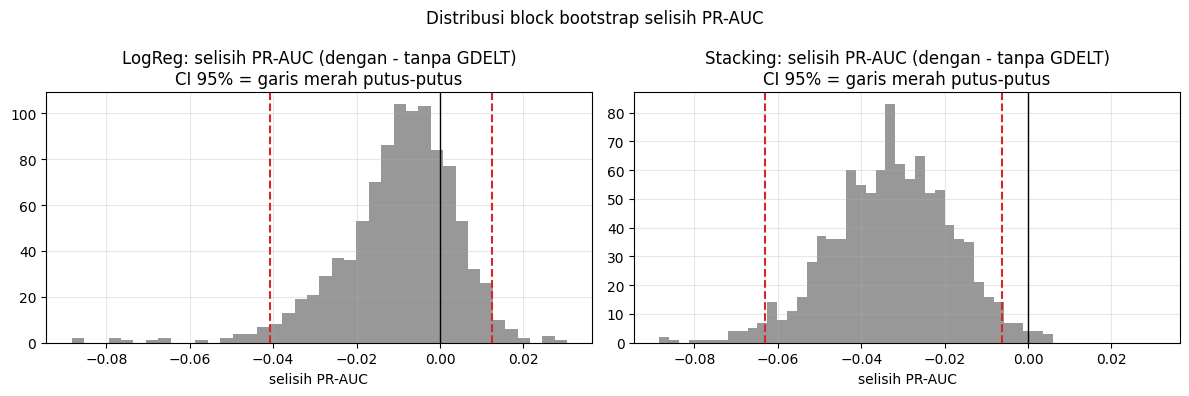

In [ ]:
def block_bootstrap(oof, a, b, fn, block=20, B=1000, seed=0):
    rng_ = np.random.default_rng(seed)
    y_, pa, pb = oof['y'].to_numpy(), oof[a].to_numpy(), oof[b].to_numpy()
    n_ = len(y_)
    nb = int(np.ceil(n_ / block))
    d = []
    for _ in range(B):
        starts = rng_.integers(0, n_ - block + 1, size=nb)
        idx = np.concatenate([np.arange(s, s + block) for s in starts])[:n_]
        if y_[idx].sum() == 0:
            continue
        d.append(fn(y_[idx], pb[idx]) - fn(y_[idx], pa[idx]))
    return np.array(d)

def delta_table(oof, B=1000):
    rows, dists = [], {}
    for fam in ['LogReg', 'Stacking']:
        a, b = f'{fam} tanpa GDELT', f'{fam} dengan GDELT'
        for name, fn in [('PR-AUC', average_precision_score), ('Brier', brier_score_loss)]:
            d = block_bootstrap(oof, a, b, fn, B=B)
            obs = fn(oof['y'], oof[b]) - fn(oof['y'], oof[a])
            rows.append({'model': fam, 'metrik': name, 'selisih': obs,
                         'CI95 bawah': np.percentile(d, 2.5), 'CI95 atas': np.percentile(d, 97.5),
                         'P(selisih>0)': (d > 0).mean()})
            dists[(fam, name)] = d
    return pd.DataFrame(rows).set_index(['model', 'metrik']), dists

delta3, dist3 = delta_table(oof3)
display(delta3.round(4))
print('Catatan: untuk PR-AUC, selisih > 0 = GDELT membantu. Untuk Brier, selisih < 0 = GDELT membantu '
      '(Brier makin kecil makin baik).')

fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
for a, fam in zip(ax, ['LogReg', 'Stacking']):
    d = dist3[(fam, 'PR-AUC')]
    a.hist(d, bins=40, color='tab:gray', alpha=0.8)
    a.axvline(0, c='k', lw=1)
    a.axvline(np.percentile(d, 2.5), c='tab:red', ls='--'); a.axvline(np.percentile(d, 97.5), c='tab:red', ls='--')
    a.set_title(f'{fam}: selisih PR-AUC (dengan - tanpa GDELT)\nCI 95% = garis merah putus-putus')
    a.set_xlabel('selisih PR-AUC')
fig.suptitle('Distribusi block bootstrap selisih PR-AUC')
plt.tight_layout(); plt.show()

In [ ]:
RUN_ROBUSTNESS = True
if RUN_ROBUSTNESS:
    t0 = time.time()
    oof4 = run_walk_forward('shock4')
    print(f'\nSelesai dalam {(time.time() - t0) / 60:.1f} menit')
    oof4.reset_index().to_parquet(f'{BASE}/processed/oof_shock4.parquet', index=False)
    tbl4 = metric_table(oof4)
    display(tbl4.round(4))
    print(f"Base rate shock4 = {oof4['y'].mean():.3f}")
    delta4, _ = delta_table(oof4)
    display(delta4.round(4))

  [shock4] fold 1/6 selesai (9 dtk)
  [shock4] fold 2/6 selesai (11 dtk)
  [shock4] fold 3/6 selesai (13 dtk)
  [shock4] fold 4/6 selesai (13 dtk)
  [shock4] fold 5/6 selesai (14 dtk)
  [shock4] fold 6/6 selesai (14 dtk)

Selesai dalam 1.2 menit


,PR-AUC,ROC-AUC,Brier
model,,,
Base rate,0.0438,0.4414,0.0436
LogReg tanpa GDELT,0.0583,0.6256,0.0573
LogReg dengan GDELT,0.0582,0.6239,0.0589
Stacking tanpa GDELT,0.0412,0.4909,0.0600
Stacking dengan GDELT,0.0465,0.5446,0.0560


Base rate shock4 = 0.044


selisih  CI95 bawah  CI95 atas  P(selisih>0)
model    metrik                                              
LogReg   PR-AUC  -0.0001     -0.0052     0.0095         0.505
         Brier    0.0016     -0.0002     0.0036         0.957
Stacking PR-AUC   0.0053      0.0015     0.0124         0.994
         Brier   -0.0040     -0.0082     0.0001         0.028

## 9. Interpretasi (SHAP) dan studi kasus

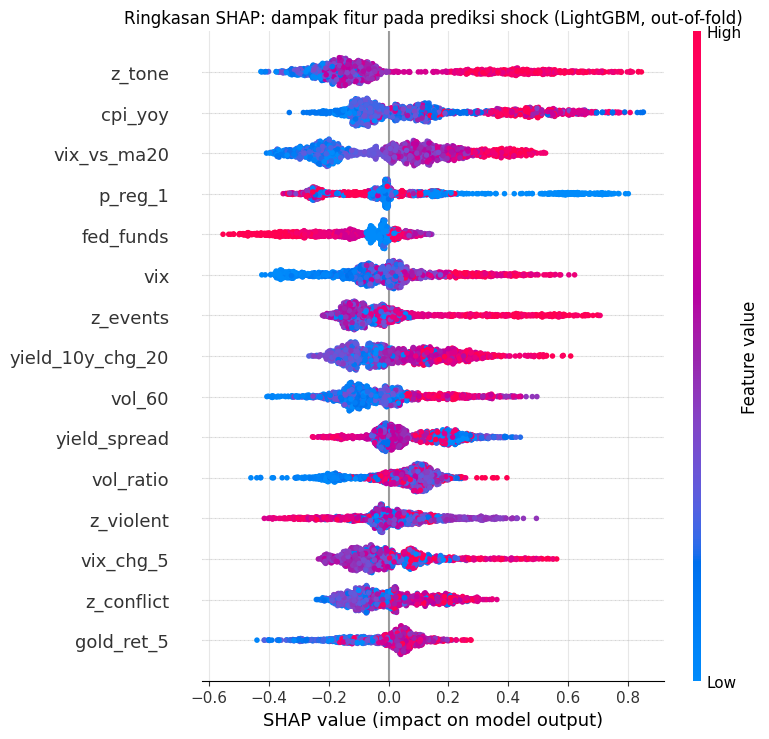

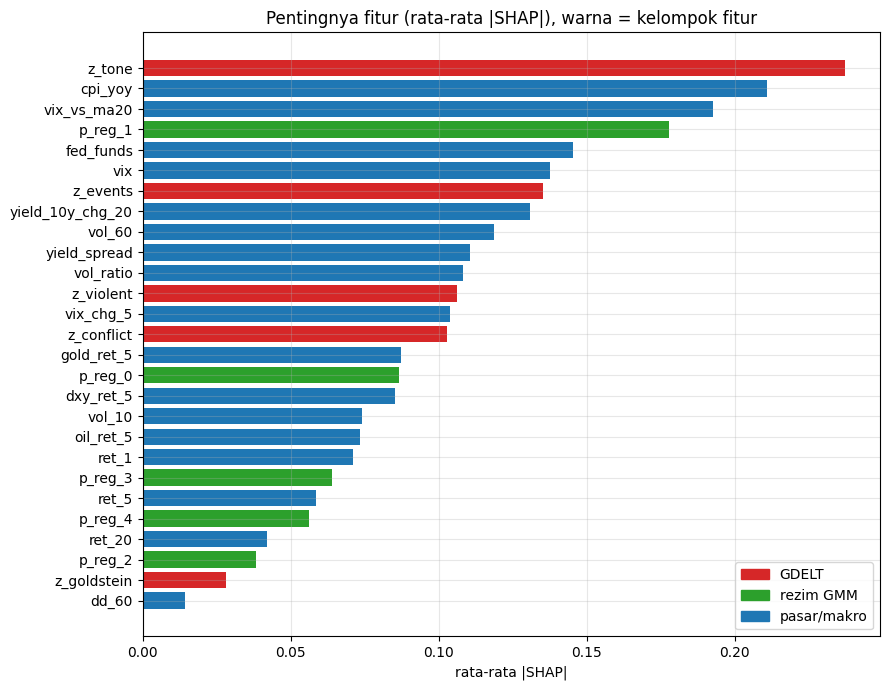

Porsi total |SHAP| per kelompok (%):
GDELT          21.8
pasar/makro    63.1
rezim GMM      15.1


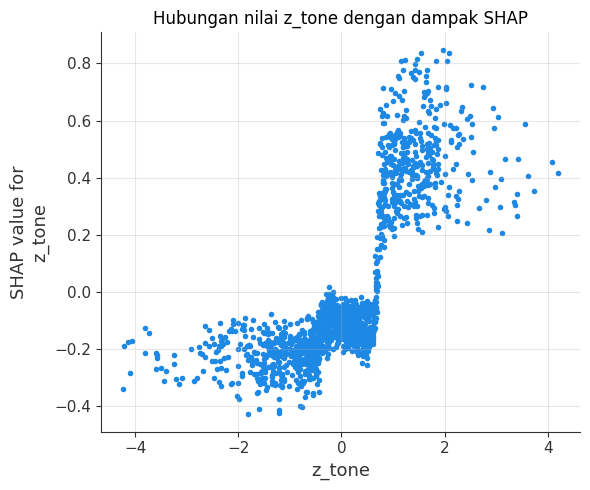

In [ ]:
import shap
FEATURES_ALL = MARKET_FEATURES + [f'p_reg_{i}' for i in range(K_REGIME)] + GDELT_FEATURES
sv_parts, X_parts = [], []
for k, (tr_idx, te_idx) in enumerate(splits, 1):
    tr, te = data.iloc[tr_idx], data.iloc[te_idx]
    proba = fit_regime(tr, K_REGIME)
    Xtr = np.column_stack([tr[MARKET_FEATURES].to_numpy(float), proba(tr), tr[GDELT_FEATURES].to_numpy(float)])
    Xte = np.column_stack([te[MARKET_FEATURES].to_numpy(float), proba(te), te[GDELT_FEATURES].to_numpy(float)])
    mdl = make_lgbm().fit(Xtr, tr['shock3'].to_numpy(int))
    sv = shap.TreeExplainer(mdl).shap_values(Xte)
    if isinstance(sv, list):
        sv = sv[1]
    sv = np.asarray(sv)
    if sv.ndim == 3:
        sv = sv[:, :, 1]
    sv_parts.append(sv); X_parts.append(Xte)
SV = np.vstack(sv_parts)
XS = pd.DataFrame(np.vstack(X_parts), columns=FEATURES_ALL)

plt.close('all')
shap.summary_plot(SV, XS, max_display=15, show=False)
plt.title('Ringkasan SHAP: dampak fitur pada prediksi shock (LightGBM, out-of-fold)')
plt.tight_layout(); plt.show()


imp = pd.Series(np.abs(SV).mean(axis=0), index=FEATURES_ALL).sort_values()
def grp(f):
    return 'GDELT' if f in GDELT_FEATURES else ('rezim GMM' if f.startswith('p_reg') else 'pasar/makro')
cmap_g = {'GDELT': 'tab:red', 'rezim GMM': 'tab:green', 'pasar/makro': 'tab:blue'}
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(imp.index, imp.values, color=[cmap_g[grp(f)] for f in imp.index])
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=l) for l, c in cmap_g.items()], loc='lower right')
ax.set_xlabel('rata-rata |SHAP|')
ax.set_title('Pentingnya fitur (rata-rata |SHAP|), warna = kelompok fitur')
plt.tight_layout(); plt.show()
share = (imp.groupby(grp).sum() / imp.sum() * 100).round(1)
print('Porsi total |SHAP| per kelompok (%):'); print(share.to_string())

# Chart 22: dependence fitur GDELT terpenting
top_g = imp[[f for f in imp.index if f in GDELT_FEATURES]].idxmax()
plt.close('all')
shap.dependence_plot(top_g, SV, XS, interaction_index=None, show=False)
plt.title(f'Hubungan nilai {top_g} dengan dampak SHAP')
plt.tight_layout(); plt.show()

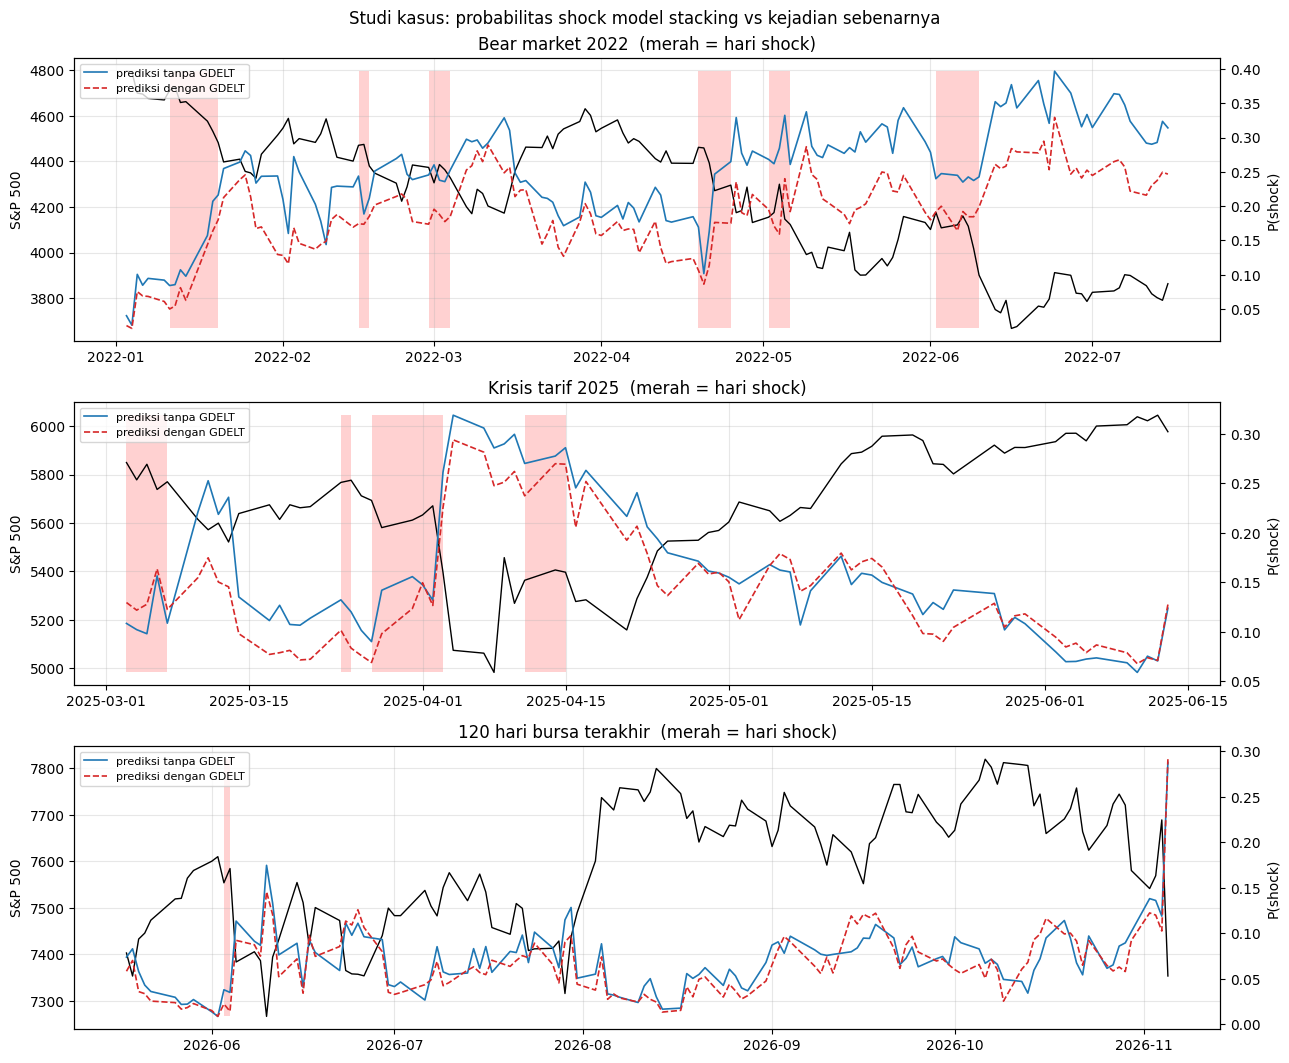

In [ ]:
# ---------- Chart 23: studi kasus, probabilitas prediksi di sekitar periode krisis ----------
windows = [('Bear market 2022', '2022-01-03', '2022-07-15'),
           ('Krisis tarif 2025', '2025-03-01', '2025-06-15'),
           ('120 hari bursa terakhir', None, None)]
fig, axes = plt.subplots(len(windows), 1, figsize=(13, 3.6 * len(windows)))
for ax, (name, a, b) in zip(axes, windows):
    sub = oof3.loc[a:b] if a else oof3.iloc[-120:]
    if len(sub) < 20:
        ax.set_visible(False)
        continue
    px = aligned['sp500_close'].reindex(sub.index)
    ax.plot(sub.index, px, color='k', lw=1)
    ax.fill_between(sub.index, px.min(), px.max(), where=(sub['y'] == 1).to_numpy(),
                    color='red', alpha=0.18, linewidth=0)
    ax.set_title(f'{name}  (merah = hari shock)'); ax.set_ylabel('S&P 500')
    ax2 = ax.twinx(); ax2.grid(False)
    ax2.plot(sub.index, sub['Stacking tanpa GDELT'], color='tab:blue', lw=1.2, label='prediksi tanpa GDELT')
    ax2.plot(sub.index, sub['Stacking dengan GDELT'], color='tab:red', lw=1.2, ls='--', label='prediksi dengan GDELT')
    ax2.set_ylabel('P(shock)'); ax2.legend(loc='upper left', fontsize=8)
fig.suptitle('Studi kasus: probabilitas shock model stacking vs kejadian sebenarnya')
plt.tight_layout(); plt.show()

## 10. Ringkasan dan ekspor

In [ ]:
def verdict(lo, hi, higher_is_better=True):
    if (lo > 0) if higher_is_better else (hi < 0):
        return 'GDELT MENAMBAH (CI 95% seluruhnya di sisi yang menguntungkan)'
    if (hi < 0) if higher_is_better else (lo > 0):
        return 'GDELT MERUGIKAN'
    return 'tidak dapat dibedakan dari nol'

print(f'Target utama shock3: base rate {base_rate:.1%}, {int(oof3["y"].sum())} hari shock out-of-fold\n')
display(tbl3.round(4))
for fam in ['LogReg', 'Stacking']:
    r = delta3.loc[(fam, 'PR-AUC')]
    print(f"{fam:9s} selisih PR-AUC = {r['selisih']:+.4f}  CI95 [{r['CI95 bawah']:+.4f}, {r['CI95 atas']:+.4f}]  "
          f"-> {verdict(r['CI95 bawah'], r['CI95 atas'])}")
if RUN_ROBUSTNESS:
    print('\nUji ketahanan shock4:')
    for fam in ['LogReg', 'Stacking']:
        r = delta4.loc[(fam, 'PR-AUC')]
        print(f"{fam:9s} selisih PR-AUC = {r['selisih']:+.4f}  CI95 [{r['CI95 bawah']:+.4f}, {r['CI95 atas']:+.4f}]  "
              f"-> {verdict(r['CI95 bawah'], r['CI95 atas'])}")
print('\nPorsi |SHAP| kelompok GDELT: ', share.get('GDELT', 0), '%')
print('Ingat: 2 keluarga model x 2 target = 4 perbandingan; satu CI yang sedikit di atas nol bukan bukti kuat.')

Target utama shock3: base rate 9.7%, 147 hari shock out-of-fold



,PR-AUC,ROC-AUC,Brier
model,,,
Base rate,0.0804,0.3487,0.0895
LogReg tanpa GDELT,0.1668,0.6725,0.0958
LogReg dengan GDELT,0.1570,0.6629,0.0992
Stacking tanpa GDELT,0.1516,0.6271,0.0919
Stacking dengan GDELT,0.1178,0.5802,0.0927


LogReg    selisih PR-AUC = -0.0098  CI95 [-0.0408, +0.0126]  -> tidak dapat dibedakan dari nol
Stacking  selisih PR-AUC = -0.0337  CI95 [-0.0631, -0.0063]  -> GDELT MERUGIKAN

Uji ketahanan shock4:
LogReg    selisih PR-AUC = -0.0001  CI95 [-0.0052, +0.0095]  -> tidak dapat dibedakan dari nol
Stacking  selisih PR-AUC = +0.0053  CI95 [+0.0015, +0.0124]  -> GDELT MENAMBAH (CI 95% seluruhnya di sisi yang menguntungkan)

Porsi |SHAP| kelompok GDELT:  21.8 %
Ingat: 2 keluarga model x 2 target = 4 perbandingan; satu CI yang sedikit di atas nol bukan bukti kuat.


In [ ]:
# ---------- Simpan tabel dan unduh semua grafik ----------
import shutil
tbl3.to_csv(f'{BASE}/processed/metrics_shock3.csv')
delta3.to_csv(f'{BASE}/processed/delta_shock3.csv')
pf.to_csv(f'{BASE}/processed/per_fold_shock3.csv')
if RUN_ROBUSTNESS:
    tbl4.to_csv(f'{BASE}/processed/metrics_shock4.csv')
    delta4.to_csv(f'{BASE}/processed/delta_shock4.csv')

zip_path = shutil.make_archive(f'{BASE}/hasil_chart', 'zip', FIG_DIR)
print('Jumlah grafik:', len(os.listdir(FIG_DIR)))
print('Arsip grafik:', zip_path)
try:
    from google.colab import files
    files.download(zip_path)
except Exception as e:
    print('Unduh otomatis dilewati:', e)

Jumlah grafik: 24
Arsip grafik: /content/drive/MyDrive/geomacro/hasil_chart.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>